#### Découverte des données

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes")

print(path)

/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes


In [ ]:
# !pip install ultralytics
import torch
import ultralytics
import cv2
import pandas as pd
import numpy as np
import warnings
import os
import matplotlib.pyplot as plt
import random
warnings.simplefilter('ignore')
from collections import Counter
from pathlib import Path
import shutil

#### Vérification et nettoyage

In [23]:
DATASET_DIR = Path(path)

WORK_DIR = Path("/kaggle/working/NeuroVisoon_AI")

WORK_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset source present : ", DATASET_DIR.exists())
print("Dataset sourcede Travail present : ", WORK_DIR.exists())
print("Chemin de Travail: ", DATASET_DIR.exists())

Dataset source present :  True
Dataset sourcede Travail present :  True
Chemin de Travail:  True


In [24]:
classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

for classe in classes:
      (WORK_DIR / "Test" / classe / "images").mkdir(parents=True, exist_ok=True)
      (WORK_DIR / "Test" / classe / "labels").mkdir(parents=True, exist_ok=True)

print('Dossiers crées dans ', WORK_DIR / 'Test')

Dossiers crées dans  /kaggle/working/NeuroVisoon_AI/Test


In [26]:
for dossier in [DATASET_DIR, DATASET_DIR / 'Train', DATASET_DIR / 'Val', WORK_DIR / 'Test']:
      print(f"\n ---{dossier}---")
      if dossier.exists():
            for element in list(dossier.iterdir())[:15]:
                  print(element.name)
      else:
            print("Ce dossier n'existe pas.")


 ---/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes---
Train
Val

 ---/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Train---
Glioma
Meningioma
No Tumor
Pituitary

 ---/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val---
Glioma
Meningioma
No Tumor
Pituitary

 ---/kaggle/working/NeuroVisoon_AI/Test---
Pituitary
Meningioma
No Tumor
Glioma


In [36]:
EXTENSIONS_IMAGES = {".jpg", ".jpeg", ".png", ".bmp"}
for split in ["Train", "Val"]:
      split_dir = DATASET_DIR /split

      print(f"\n{"="*20} {split} {"=" * 20}")

      for class_dir in sorted(split_dir.iterdir()):
            if not class_dir.is_dir():
                  continue
            print(f"\nClasse : {class_dir.name}")

            for sous_dossier in ['images', 'labels']:
                  dossier = class_dir / sous_dossier

                  if not dossier.is_dir():
                        print(f"{sous_dossier} : Dossier Introuvable")
                        continue
                  
                  fichiers = [fichier for fichier in dossier.iterdir() if fichier.is_file()]

                  if sous_dossier == 'images':

                        fichiers_valides = [
                              fichier for fichier in fichiers
                              if fichier.suffix.lower() in EXTENSIONS_IMAGES
                        ]
                  else:
                        fichiers_valides = [
                              fichier for fichier in fichiers
                              if fichier.suffix.lower() == ".txt"
                        ]

                  extensions = Counter(fichier.suffix.lower()
                              for fichier in fichiers
                        )

                  print(f"\nClasse : {sous_dossier}")
                  print(f"Nombre de fichiers totals : {len(fichiers)}")
                  print(f"Nombre de fichiers attendus : {len(fichiers_valides)}")
                  print(f"Extensions : {dict(extensions)}")

                  print("Exemples:")
                  for fichier in fichiers[:5]:
                        print(" ", fichier.name)
            



==================== Train ====================

Classe : Glioma

Classe : images
Nombre de fichiers totals : 1153
Nombre de fichiers attendus : 1153
Extensions : {'.jpg': 1153}
Exemples:
  Te-glTr_0000.jpg
  Te-glTr_0005.jpg
  Te-glTr_0007.jpg
  Te-gl_0014.jpg
  Te-gl_0015.jpg

Classe : labels
Nombre de fichiers totals : 1153
Nombre de fichiers attendus : 1153
Extensions : {'.txt': 1153}
Exemples:
  Te-glTr_0000.txt
  Te-glTr_0005.txt
  Te-glTr_0007.txt
  Te-gl_0014.txt
  Te-gl_0015.txt

Classe : Meningioma

Classe : images
Nombre de fichiers totals : 1449
Nombre de fichiers attendus : 1449
Extensions : {'.jpg': 1449}
Exemples:
  Tr-meTr_0008.jpg
  Tr-meTr_0009.jpg
  Tr-me_0010.jpg
  Tr-me_0011.jpg
  Tr-me_0017.jpg

Classe : labels
Nombre de fichiers totals : 1449
Nombre de fichiers attendus : 1449
Extensions : {'.txt': 1449}
Exemples:
  Tr-meTr_0008.txt
  Tr-meTr_0009.txt
  Tr-me_0010.txt
  Tr-me_0011.txt
  Tr-me_0017.txt

Classe : No Tumor

Classe : images
Nombre de fichiers totals

In [ ]:
#Verifier la correspondance entre images et annotations

EXTENSIONS_IMAGES = {".jpg", ".jpeg", ".png", ".bmp"}

def verifier_paires(split_dir):
      results = {}

      for class_dir in sorted(split_dir.iterdir()):
            if not class_dir.is_dir():
                  continue

            images_dir = class_dir / "images"
            labels_dir = class_dir / "labels"

            if not images_dir.is_dir() or not labels_dir.is_dir():
                  print(f"Erreur Strucure inattendue : {class_dir}")
                  continue

            images = {
                  f.stem: f
                  for f in images_dir.iterdir()
                  if f.is_file() and f.suffix.lower() in EXTENSIONS_IMAGES
            }

            labels = {
                  f.stem : f
                  for f in labels_dir.iterdir()
                  if f.is_file() and f.suffix.lower() == '.txt'
            }

            images_sans_labels = sorted(set(images) - set(labels))
            labels_sans_images = sorted(set(labels) - set(images))


            results[class_dir.name] = {
                  "images" : len(images),
                  "labels" : len(labels),
                  "images_sans_labels" : images_sans_labels,
                  "labels_sans_images" : labels_sans_images,
            }

            print(f"\n---{class_dir.name}---")
            print(f"Images : {len(images)}")
            print(f"Annotations : {len(labels)}")
            print(f"Images sans annotations: {len(images_sans_labels)}")
            print(f"Annotations sans images: {len(labels_sans_images)}")

            if images_sans_labels:
                  print("Exemple d'images sans annotation : ", images_sans_labels[:5])
            if labels_sans_images:
                  print("Exemple d'annotations sans image : ", labels_sans_images[:5])
      return results

results_train = verifier_paires(DATASET_DIR / 'Train')
results_val = verifier_paires(DATASET_DIR / 'Val')


---Glioma---
Images : 1153
Annotations : 1153
Images sans annotations: 0
Annotations sans images: 0

---Meningioma---
Images : 1449
Annotations : 1449
Images sans annotations: 0
Annotations sans images: 0

---No Tumor---
Images : 711
Annotations : 711
Images sans annotations: 0
Annotations sans images: 0

---Pituitary---
Images : 1424
Annotations : 1424
Images sans annotations: 0
Annotations sans images: 0

---Glioma---
Images : 136
Annotations : 136
Images sans annotations: 0
Annotations sans images: 0

---Meningioma---
Images : 140
Annotations : 140
Images sans annotations: 0
Annotations sans images: 0

---No Tumor---
Images : 100
Annotations : 100
Images sans annotations: 2
Annotations sans images: 2
Exemple d'images sans annotation :  ['image(55)', 'image(61)']
Exemple d'annotations sans image :  ['image(53)', 'image(60)']

---Pituitary---
Images : 136
Annotations : 136
Images sans annotations: 0
Annotations sans images: 0


In [45]:
non_tumor_val = DATASET_DIR / 'Val' / 'No Tumor'

images_dir = non_tumor_val /'images'
labels_dir = non_tumor_val /'labels'

noms_a_verifier = ['image(55)', 'image(61)','image(53)', 'image(60)']

for nom in noms_a_verifier:
      print(f"\n---{nom}---")

      for dossier in[images_dir, labels_dir]:
            fichiers = list(dossier.glob(f'{nom}.*'))

            if fichiers:
                  for fichier in fichiers:
                        print(f"Trouvé : {fichier.name}")
            else:
                  print(f"Aucun fichier correspondant dans {dossier.name}")



---image(55)---
Trouvé : image(55).jpg
Aucun fichier correspondant dans labels

---image(61)---
Trouvé : image(61).jpg
Aucun fichier correspondant dans labels

---image(53)---
Aucun fichier correspondant dans images
Trouvé : image(53).txt

---image(60)---
Aucun fichier correspondant dans images
Trouvé : image(60).txt


In [ ]:
#Visualisation des 2 labels sans images

for nom in ['image(53)', 'image(60)']:
      fichier_label = labels_dir / f"{nom}.txt"

      print(f"\n ---{fichier_label.name} ---")

      if fichier_label.exists():
            contenue = fichier_label.read_text(encoding='utf-8').strip()

            if contenue:
                  print(contenue)
            else:
                  print("Annotation vide")


 ---image(53).txt ---
2 0.506818 0.494545 0.913636 0.930909

 ---image(60).txt ---
2 0.502119 0.514831 0.572034 0.682203


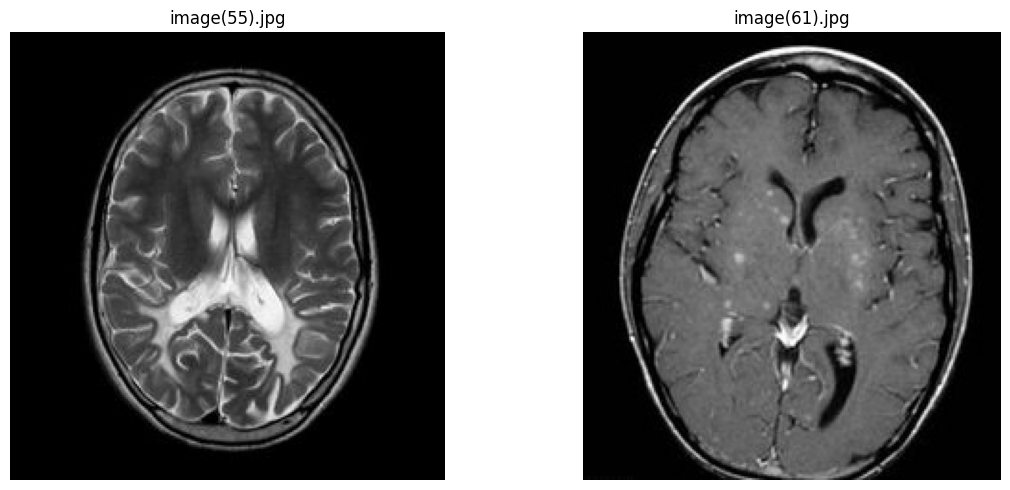

In [ ]:
#Visualisation des 2 images sans annotations
images_a_verifier = [
      images_dir / "image(55).jpg",
      images_dir / "image(61).jpg",
]

fig, axes = plt.subplots(1, 2, figsize=(12,5))

for ax, chemin in zip(axes, images_a_verifier):
      image = cv2.imread(str(chemin))

      if image is None:
            ax.set_title(f"Impossible de lire\n{chemin.name}")
            ax.axis("off")
            continue

      image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

      ax.imshow(image_rgb, cmap='gray')
      ax.set_title(chemin.name)
      ax.axis('off')

plt.tight_layout()


In [52]:

exemples = [
    "Tr-no_0025",
    "Tr-no_0042",
    "Tr-no_0048",
]

for nom in exemples:
    fichier = labels_dir / f"{nom}.txt"

    print(f"\n--- {nom}.txt ---")

    if fichier.exists():
        contenu = fichier.read_text(encoding="utf-8").strip()
        print(contenu if contenu else "Annotation vide")
    else:
        print("Annotation introuvable")



--- Tr-no_0025.txt ---
2 0.505656 0.504525 0.653846 0.760181

--- Tr-no_0042.txt ---
2 0.497881 0.513761 0.605932 0.807339

--- Tr-no_0048.txt ---
2 0.495726 0.520089 0.581197 0.700893


In [ ]:
def create_clean_dataset_dir(DATASET_DIR):
      CLEAN_DATASET_DIR = Path('/kaggle/working/NeuroVision_AI/dataset_cleaned')

      if CLEAN_DATASET_DIR.exists():
            print('La copie nettoyée existe déja:', CLEAN_DATASET_DIR)
            print("verifier son contenue avant de continuer")

      else:
            # shutil.copytree() copie un dossier et son contenu vers un autre emplacement.
            shutil.copytree(DATASET_DIR, CLEAN_DATASET_DIR)
            print('Copie crée avec success')
      return CLEAN_DATASET_DIR
CLEAN_DATASET_DIR = create_clean_dataset_dir(DATASET_DIR)


In [ ]:
def remove_misMatch_images(fichiers_a_supprimer):
      for fichier in fichiers_a_supprimer:
            if fichier.is_file():
                  fichier.unlink()
                  print('Supprimé:', fichier.relative_to(CLEAN_DATASET_DIR))
            else:
                  print('Fichier introuvable:', fichier)

dossier_no_tumor = CLEAN_DATASET_DIR / "Val" / "No Tumor"

fichiers_a_supprimer = [
      dossier_no_tumor / "images" / "image(55).jpg",
      dossier_no_tumor / "images" / "image(61).jpg",
      dossier_no_tumor / "labels" / "image(53).txt",
      dossier_no_tumor / "labels" / "image(60).txt",
]

remove_misMatch_images(fichiers_a_supprimer=fichiers_a_supprimer)

def verify_removed_files(fichiers):
      for fichier in fichiers:
            statut = "Encore présent" if fichier.exists() else "Supprimé"
            print(f"{fichier.name} --> {statut}")

verify_removed_files(fichiers_a_supprimer)

In [ ]:
nbr_classes = 4

CLASSES_IDS_VALIDES = set(range(nbr_classes))
print('Identifiants autoris"es pour les classes:', CLASSES_IDS_VALIDES)

Identifiants autoris"es pour les classes: {0, 1, 2, 3}


In [ ]:
import math

def verifier_fichier_annotation(fichier, classes_ids_valides):
      erreurs = []

      contenue = fichier.read_text(encoding='utf-8')

      if not contenue:
            return erreurs

      for numero_ligne, ligne in enumerate(contenue.splitlines(), start=1):

            valeurs = ligne.split()

            if(len(valeurs) != 5):
                  erreurs.append(
                        f"Line{numero_ligne} : "
                        f" {len(valeurs)} valeurs au lieu de 5"
                  )
                  continue

            class_str, *cordonnees_str = valeurs

            try:
                  classe_float = float(class_str)

                  if not math.isfinite(classe_float) or not classe_float.is_integer():
                        erreurs.append(
                              f"Ligne {numero_ligne} : classe non entier"
                        )
                        continue
                  classe = int(classe_float)

            except ValueError:
                  erreurs.append(
                        f"Ligne {numero_ligne} : classe non numerique"
                  )
                  continue

            if classe not in classes_ids_valides:
                  erreurs.append(
                        f"Ligne {numero_ligne} : class invalide ({classe})"
                  )
                  continue

            try:
                  x_center, y_center, largeur, hauteur = map(float, cordonnees_str)

            except ValueError:
                  erreurs.append(
                        f"Ligne {numero_ligne} : classe non numerique"
                        )
                  continue

            conrdonnees = [x_center, y_center, largeur, hauteur]

            if not all(math.isfinite(v) for v in conrdonnees):
                  erreurs.append(
                        f"Ligne {numero_ligne} : valeur non finie"
                  )
                  continue

            if not (0 <= x_center <= 1 and 0 <= y_center <= 1):
                  erreurs.append(
                        f"Ligne {numero_ligne} : centre hors limites"
                  )
            if not (0 <= largeur <= 1 and 0 <= hauteur <= 1):
                  erreurs.append(
                  f"Ligne {numero_ligne} : largeur ou hauteur hors limites"
                  )

            if (
                  0 <= largeur <= 1 
                  and 0 <= hauteur <= 1
                  and
                  (
                        x_center - largeur / 2 < 0
                        or x_center + largeur / 2 > 1
                        or y_center - hauteur / 2 < 0
                        or y_center + hauteur / 2 > 1
                  )
            ):
                  erreurs.append(
                        f"Ligne {numero_ligne} : boite deppasant les limites"
                  )
      return erreurs

In [ ]:

def auditer_annotations(CLEAN_DATASET_DIR):
      total_fichiers = 0
      total_erreurs = 0
      fichiers_invalides = []

      for split in ["Train", "Val"]:
            split_dir = CLEAN_DATASET_DIR / split
            print(f"\n{'=' * 15} {split} {'=' * 15}")

            for classe_dir in sorted(split_dir.iterdir()):
                  if not classe_dir.is_dir():
                        continue

                  labels_dir = classe_dir / "labels"

                  if not labels_dir.is_dir():
                        print("Dossier labels introuvable :", classe_dir)
                        continue

                  for fichier in sorted(labels_dir.glob("*.txt")):
                        total_fichiers += 1

                        erreurs = verifier_fichier_annotation(
                        fichier,
                        CLASSES_IDS_VALIDES
                        )

                        if erreurs:
                              fichiers_invalides.append(fichier)
                              total_erreurs += len(erreurs)

                              print(f"\nFichier : {fichier.relative_to(CLEAN_DATASET_DIR)}")
                              for erreur in erreurs:
                                    print("  -", erreur)

      print("\n========== BILAN ==========")
      print("Fichiers TXT vérifiés :", total_fichiers)
      print("Fichiers contenant des erreurs :", len(fichiers_invalides))
      print("Nombre total d'erreurs :", total_erreurs)

      return fichiers_invalides


fichiers_invalides = auditer_annotations(CLEAN_DATASET_DIR)


In [ ]:
CLASS_NAMES = {
      0: "Glioma",
      1: "Meningioma",
      2: "No Tumor",
      3: "Pituitary",
}
print(CLASS_NAMES)

In [ ]:
def afficher_image_bbox(image_path, label_path):

      image = cv2.imread(str(image_path))

      if image is None:
            print(f"Image impossible de lire : {image_path}")
            return

      image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

      hauteur, largeur = image.shape[:2]

      with open (label_path, 'r', encoding='utf-8') as fichier:
            lignes = fichier.readlines()

            for ligne in lignes:
                  valeurs  = ligne.split()

                  if len(valeurs) != 5:
                        continue

                  classe, x_center, y_center, w, h = map(float, valeurs)

                  x_center *= largeur
                  y_center *= hauteur
                  w *=largeur
                  h *= hauteur

                  x1 = int(x_center - w / 2) 
                  y1 = int(y_center - h / 2) 
                  x2 = int(x_center + w / 2) 
                  y2 = int(y_center + h / 2) 

                  x1 = max(0, min(x1, largeur -1))
                  y1 = max(0, min(y1, hauteur -1))
                  x2 = max(0, min(x2, largeur -1))
                  y2 = max(0, min(y2, hauteur -1))

                  classe_id = int(classe)

                  nom_classe = CLASS_NAMES.get(classe_id, f'Classe {classe_id}')

                  cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

                  cv2.putText(
                        image,
                        nom_classe,
                        (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        (255, 0, 0),
                        2
                  )


                  plt.figure(figsize=(7,7))
                  plt.imshow(image)
                  plt.title(image_path.name)
                  plt.axis('off')
                  plt.show()


In [ ]:
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

for classe in CLASSES:
      dossier_images = CLEAN_DATASET_DIR / "Train" / classe / "images"
      dossier_labels = CLEAN_DATASET_DIR / "Train" / classe / "labels"

      images = [
            p for p in dossier_images.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
            and (dossier_labels / f"{p.stem}.txt").is_file()
      ]

      if not images:
            print(f"Aucune image annotée trouvée pour {classe}")
            continue

      image_path = random.choice(images)
      label_path = dossier_labels / f"{image_path.stem}.txt"

      print(f"Classe du dossier : {classe}")
      afficher_image_bbox(image_path, label_path)

In [ ]:
# Analyser la distribution des classes
from pathlib import Path
import pandas as pd

CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
SPLITS = ["Train", "Val"]

statistiques = []

for split in SPLITS:
      for classe in CLASSES:
            dossier_images = CLEAN_DATASET_DIR / split / classe / "images"

            images = [
                  fichier
                  for fichier in dossier_images.iterdir()
                  if fichier.is_file()
                  and fichier.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
            ]

            statistiques.append({
                  "Split": split,
                  "Classe": classe,
                  "Nombre_images": len(images)
            })

df_stats = pd.DataFrame(statistiques)

display(df_stats)

In [ ]:
# Visualiser la répartition des images
tableau = df_stats.pivot(
      index="Classe",
      columns="Split",
      values="Nombre_images"
)

tableau.plot(
      kind="bar",
      figsize=(10, 6),
      rot=0
)

plt.title("Distribution des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.legend(title="Ensemble")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Vérifier les annotations vides
annotations_vides = []

for split in SPLITS:
      for classe in CLASSES:
            dossier_labels = CLEAN_DATASET_DIR / split / classe / "labels"

            for fichier in dossier_labels.glob("*.txt"):
                  if fichier.read_text(encoding="utf-8").strip() == "":
                        annotations_vides.append({
                              "Split": split,
                              "Classe_dossier": classe,
                              "Fichier": fichier.name
                        })

      df_vides = pd.DataFrame(
      annotations_vides,
      columns=["Split", "Classe_dossier", "Fichier"]
)

print("Nombre d'annotations vides :", len(df_vides))
display(df_vides)

#### Organisation du dataset

#### Augmentation des données

#### Entraînement de YOLOv

#### Évaluation et analyse des erreurs

#### Suivi des expériences avec MLflow